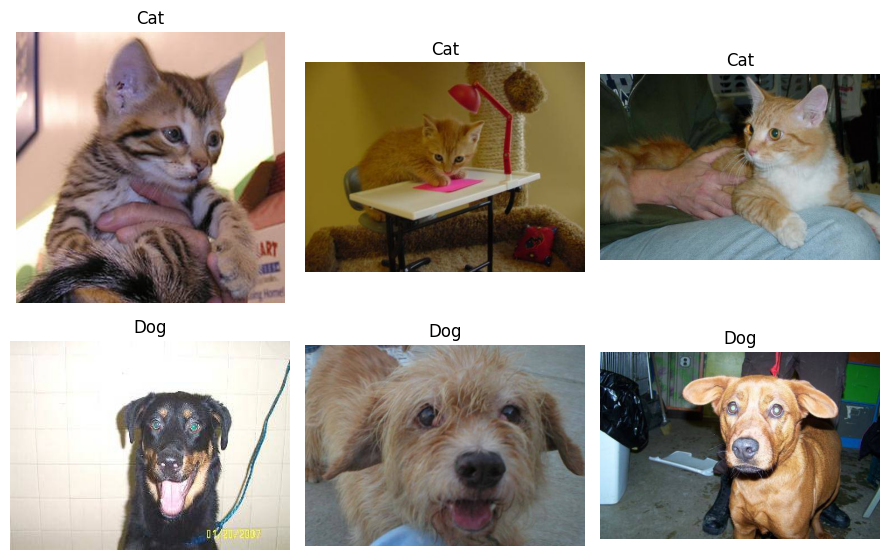

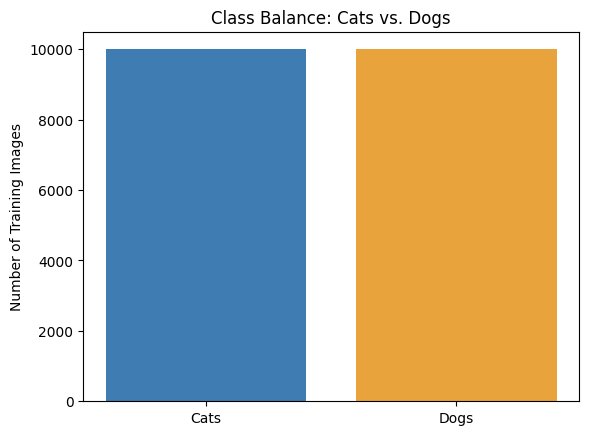

Found 20000 files belonging to 2 classes.
Using 16000 files for training.


2026-10-18 14:55:50.358881: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
Class names: ['cats', 'dogs']
Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 116s 228ms/step - accuracy: 0.6621 - loss: 0.6067 - val_accuracy: 0.7405 - val_loss: 0.5284
Epoch 2/5
417/500 ━━━━━━━━━━━━━━━━━━━━ 15s 189ms/step - accuracy: 0.7466 - loss: 0.5114

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import tensorflow as tf
from tensorflow.keras import layers, models

# Dataset paths
TRAIN_DIR = "/kaggle/input/datasets/salader/dogsvscats/train"
TEST_DIR = "//kaggle/input/datasets/salader/dogsvscats/test"

# Step 1: Visualise sample images BEFORE modelling
cat_files = os.listdir(os.path.join(TRAIN_DIR, "cats"))[:3]
dog_files = os.listdir(os.path.join(TRAIN_DIR, "dogs"))[:3]

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for i, fname in enumerate(cat_files):
    img = mpimg.imread(os.path.join(TRAIN_DIR, "cats", fname))
    axes[0, i].imshow(img)
    axes[0, i].set_title("Cat")
    axes[0, i].axis("off")

for i, fname in enumerate(dog_files):
    img = mpimg.imread(os.path.join(TRAIN_DIR, "dogs", fname))
    axes[1, i].imshow(img)
    axes[1, i].set_title("Dog")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# Step 2: Visualise class balance
num_cats = len(os.listdir(os.path.join(TRAIN_DIR, "cats")))
num_dogs = len(os.listdir(os.path.join(TRAIN_DIR, "dogs")))

plt.bar(
    ["Cats", "Dogs"],
    [num_cats, num_dogs],
    color=["#3E7CB1", "#E8A33D"]
)
plt.ylabel("Number of Training Images")
plt.title("Class Balance: Cats vs. Dogs")
plt.show()

# Step 3: Load images as labelled, resized datasets
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="binary"
)

# Check class order
print("Class names:", train_ds.class_names if hasattr(train_ds, "class_names") else ["cats", "dogs"])

# Normalize pixel values from 0-255 to 0-1
normalize = layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(lambda x, y: (normalize(x), y))
val_ds = val_ds.map(lambda x, y: (normalize(x), y))

# Step 4: Build a small CNN classifier
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Step 5: Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

# Step 6: Evaluate the model
val_loss, val_accuracy = model.evaluate(val_ds)

print(f"Validation accuracy: {val_accuracy:.2%}")

# Step 7: Plot training and validation accuracy
plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs. Validation Accuracy")
plt.legend()
plt.show()
